# Evaluación integral del Trabajo Final

Este notebook es el punto de entrada único para revisar y, cuando corresponda,
reanudar el experimento de comparación entre GPT-4o mini, LLaMA 3.1 8B y
Mistral, con y sin RAG.

La apertura normal es segura: **solo lee los resultados existentes**. No llama
a OpenAI, no ejecuta Ollama, no descarga el corpus y no recalcula BERTScore. Las
operaciones con costo o carga computacional requieren cambiar controles
explícitos en la sección siguiente.

In [1]:
from pathlib import Path
import os
import subprocess
import sys

import pandas as pd
from IPython.display import Image, Markdown, display


def buscar_raiz_proyecto() -> Path:
    candidatos = [Path.cwd(), Path.cwd().parent]
    for candidato in candidatos:
        if (candidato / "scripts").is_dir() and (candidato / "data").is_dir():
            return candidato.resolve()
    raise RuntimeError("Ejecute el notebook desde proyecto/ o proyecto/notebooks/.")


PROYECTO = buscar_raiz_proyecto()
sys.path.insert(0, str(PROYECTO))
print(f"Proyecto: {PROYECTO.name}")
print(f"Python: {sys.version.split()[0]}")

Proyecto: proyecto
Python: 3.11.17


## 0. Controles de ejecución

- `resultados`: recorre toda la evaluación usando los CSV ya generados.
- `demo`: genera dos condiciones para una consulta por cada modelo indicado.
- `completo`: reanuda el plan de 1.944 respuestas desde el checkpoint.

Para una corrida completa debe escribirse además la frase de confirmación
exacta. El notebook nunca borra checkpoints: si ya están completos, los reutiliza.

In [2]:
MODO = "resultados"  # opciones: "resultados", "demo", "completo"
MODELOS_DEMO = ["llama-3.1-8b", "mistral"]
CONSULTAS_DEMO_POR_MODELO = 1

RECONSTRUIR_MUESTRA = False       # descarga Bitext; no usa modelos generativos
TRADUCIR_MUESTRA = False          # puede llamar a OpenAI si hay filas pendientes
RECONSTRUIR_CORPUS_RAG = False    # descarga Bitext; no usa modelos generativos
REVALIDAR_RECUPERACION = False    # carga el modelo de embeddings
RECALCULAR_METRICAS = False       # puede cargar BERTScore si faltan métricas
REGENERAR_FIGURAS = False
PREPARAR_EVALUACION_HUMANA = False
ANALIZAR_EVALUACION_HUMANA = False

CONFIRMAR_TRADUCCION = ""         # escribir: TRADUCIR MUESTRA
CONFIRMAR_CORRIDA_COMPLETA = ""   # escribir: EJECUTAR 1944 RESPUESTAS

if MODO not in {"resultados", "demo", "completo"}:
    raise ValueError("MODO debe ser resultados, demo o completo.")

## 1. Verificación del entorno y de los archivos

In [3]:
ARCHIVOS_REQUERIDOS = {
    "muestra": PROYECTO / "data" / "muestra_ampliada_es.csv",
    "corpus_rag": PROYECTO / "data" / "conocimiento_rag_ampliado.csv",
    "recuperacion": PROYECTO / "resultados_recuperacion_rag_ampliada.csv",
    "recuperacion_intenciones": PROYECTO / "resultados_recuperacion_rag_ampliada_por_intencion.csv",
    "resultados_crudos": PROYECTO / "resultados_experimento_ampliado.csv",
    "resultados_evaluados": PROYECTO / "resultados_experimento_ampliado_evaluados.csv",
    "resumen": PROYECTO / "resumen_experimento_ampliado.csv",
    "comparacion": PROYECTO / "comparacion_pareada_ampliada.csv",
    "hipotesis": PROYECTO / "contraste_hipotesis_rag.csv",
}

estado_archivos = pd.DataFrame(
    [
        {
            "componente": nombre,
            "archivo": ruta.relative_to(PROYECTO).as_posix(),
            "disponible": ruta.exists(),
            "tamaño_kb": round(ruta.stat().st_size / 1024, 1) if ruta.exists() else None,
        }
        for nombre, ruta in ARCHIVOS_REQUERIDOS.items()
    ]
)
display(estado_archivos)

faltantes = estado_archivos.loc[~estado_archivos["disponible"], "componente"].tolist()
if faltantes and MODO == "resultados":
    raise FileNotFoundError(f"Faltan resultados requeridos: {faltantes}")

,componente,archivo,disponible,tamaño_kb
0,muestra,data/muestra_ampliada_es.csv,True,479.9
1,corpus_rag,data/conocimiento_rag_ampliado.csv,True,122.0
2,recuperacion,resultados_recuperacion_rag_ampliada.csv,True,102.1
3,recuperacion_intenciones,resultados_recuperacion_rag_ampliada_por_inten...,True,1.6
4,resultados_crudos,resultados_experimento_ampliado.csv,True,2846.6
5,resultados_evaluados,resultados_experimento_ampliado_evaluados.csv,True,3108.0
6,resumen,resumen_experimento_ampliado.csv,True,1.2
7,comparacion,comparacion_pareada_ampliada.csv,True,3.2
8,hipotesis,contraste_hipotesis_rag.csv,True,0.9


## 2. Reconstrucción opcional de datos y corpus

Estas celdas delegan en los scripts versionados. La selección de la muestra es
reproducible (324 consultas: 12 por cada una de las 27 intenciones). La
traducción usa el checkpoint existente y solo procesa filas pendientes.

In [4]:
def ejecutar_script(nombre: str, *argumentos: str) -> None:
    comando = [sys.executable, str(PROYECTO / "scripts" / nombre), *map(str, argumentos)]
    print("Ejecutando:", " ".join(comando))
    subprocess.run(comando, cwd=PROYECTO, check=True)


if RECONSTRUIR_MUESTRA:
    ejecutar_script("construir_muestra_ampliada.py")

if TRADUCIR_MUESTRA:
    if CONFIRMAR_TRADUCCION != "TRADUCIR MUESTRA":
        raise RuntimeError("Para traducir, escriba la confirmación exacta indicada arriba.")
    ejecutar_script("traducir_muestra_ampliada.py")

if RECONSTRUIR_CORPUS_RAG:
    ejecutar_script(
        "construir_corpus_rag.py",
        "--evaluacion", PROYECTO / "data" / "muestra_ampliada_es.csv",
        "--salida", PROYECTO / "data" / "conocimiento_rag_ampliado.csv",
    )

if REVALIDAR_RECUPERACION:
    ejecutar_script(
        "validar_recuperacion_rag.py",
        "--corpus", PROYECTO / "data" / "conocimiento_rag_ampliado.csv",
        "--evaluacion", PROYECTO / "data" / "muestra_ampliada_es.csv",
        "--salida", PROYECTO / "resultados_recuperacion_rag_ampliada.csv",
    )

if not any([RECONSTRUIR_MUESTRA, TRADUCIR_MUESTRA, RECONSTRUIR_CORPUS_RAG, REVALIDAR_RECUPERACION]):
    print("Se reutilizan la muestra, el corpus y la validación existentes.")

Se reutilizan la muestra, el corpus y la validación existentes.


## 3. Auditoría de la muestra y del corpus RAG

In [5]:
muestra = pd.read_csv(ARCHIVOS_REQUERIDOS["muestra"])
corpus = pd.read_csv(ARCHIVOS_REQUERIDOS["corpus_rag"])

conteos_muestra = muestra.groupby("intent").size()
conteos_corpus = corpus.groupby("intent").size()
auditoria_datos = pd.DataFrame(
    {
        "indicador": [
            "Consultas de evaluación",
            "Intenciones de evaluación",
            "Mínimo por intención",
            "Máximo por intención",
            "Documentos RAG",
            "Intenciones del corpus RAG",
            "Documentos RAG por intención",
        ],
        "valor": [
            len(muestra),
            muestra["intent"].nunique(),
            conteos_muestra.min(),
            conteos_muestra.max(),
            len(corpus),
            corpus["intent"].nunique(),
            f"{conteos_corpus.min()}–{conteos_corpus.max()}",
        ],
    }
)
display(auditoria_datos)

assert len(muestra) == 324 and muestra["intent"].nunique() == 27
assert (conteos_muestra == 12).all()
assert len(corpus) == 81 and corpus["intent"].nunique() == 27
assert (conteos_corpus == 3).all()
print("Controles de balance y cobertura: OK")

,indicador,valor
0,Consultas de evaluación,324
1,Intenciones de evaluación,27
2,Mínimo por intención,12
3,Máximo por intención,12
4,Documentos RAG,81
5,Intenciones del corpus RAG,27
6,Documentos RAG por intención,3–3


Controles de balance y cobertura: OK


## 4. Recuperación RAG

In [6]:
recuperacion = pd.read_csv(ARCHIVOS_REQUERIDOS["recuperacion"])
recuperacion_intenciones = pd.read_csv(ARCHIVOS_REQUERIDOS["recuperacion_intenciones"])

indicadores_rag = pd.DataFrame(
    {
        "métrica": ["Hit@1", "Hit@3", "Latencia media de recuperación (ms)"],
        "valor": [
            f"{recuperacion['hit_top1'].mean():.1%}",
            f"{recuperacion['hit_top_k'].mean():.1%}",
            f"{recuperacion['latencia_recuperacion_s'].mean() * 1000:.2f}",
        ],
    }
)
display(indicadores_rag)
display(
    recuperacion_intenciones.sort_values(["hit_top1", "hit_top_k", "intent_esperado"])
    .head(8)
    .style.format({"hit_top1": "{:.1%}", "hit_top_k": "{:.1%}", "latencia_media_s": "{:.4f}"})
    .set_caption("Intenciones con menor desempeño de recuperación")
)

,métrica,valor
0,Hit@1,81.8%
1,Hit@3,96.0%
2,Latencia media de recuperación (ms),14.43


,intent_esperado,consultas,hit_top1,hit_top_k,latencia_media_s
0,track_refund,12,25.0%,66.7%,0.0146
1,change_shipping_address,12,41.7%,100.0%,0.0145
2,change_order,12,50.0%,83.3%,0.0147
3,switch_account,12,58.3%,75.0%,0.0142
4,newsletter_subscription,12,66.7%,83.3%,0.0144
5,get_invoice,12,66.7%,100.0%,0.0142
6,get_refund,12,66.7%,100.0%,0.0142
7,create_account,12,75.0%,91.7%,0.0148


## 5. Ejecución o reanudación de las generaciones

En `resultados` esta sección no genera nada. El modo `demo` usa un archivo de
salida separado y, por defecto, solo los modelos locales. El modo `completo`
requiere confirmación literal y conserva el checkpoint principal.

In [7]:
if MODO == "demo":
    if not MODELOS_DEMO:
        raise ValueError("MODELOS_DEMO no puede estar vacío.")
    ejecutar_script(
        "ejecutar_experimento_ampliado.py",
        "--modelos", *MODELOS_DEMO,
        "--limite-consultas", str(CONSULTAS_DEMO_POR_MODELO),
        "--salida", PROYECTO / "resultados_demo_notebook.csv",
    )
elif MODO == "completo":
    if CONFIRMAR_CORRIDA_COMPLETA != "EJECUTAR 1944 RESPUESTAS":
        raise RuntimeError("Falta la confirmación literal de la corrida completa.")
    ejecutar_script("ejecutar_experimento_ampliado.py", "--confirmar-corrida-completa")
else:
    print("Modo resultados: no se realizaron llamadas a modelos.")

Modo resultados: no se realizaron llamadas a modelos.


## 6. Integridad de la corrida ampliada

In [8]:
crudos = pd.read_csv(ARCHIVOS_REQUERIDOS["resultados_crudos"])
grupos = crudos.groupby(["modelo", "condicion"]).size().rename("respuestas").reset_index()
errores = int(crudos["error"].notna().sum())
vacias = int(crudos["respuesta"].isna().sum())

display(grupos)
print(f"Total: {len(crudos):,} respuestas | errores: {errores} | vacías: {vacias}")
assert len(crudos) == 1944
assert len(grupos) == 6 and (grupos["respuestas"] == 324).all()
assert errores == 0 and vacias == 0
print("Integridad del experimento: OK")

,modelo,condicion,respuestas
0,gpt-4o-mini,rag,324
1,gpt-4o-mini,sin_rag,324
2,llama-3.1-8b,rag,324
3,llama-3.1-8b,sin_rag,324
4,mistral,rag,324
5,mistral,sin_rag,324


Total: 1,944 respuestas | errores: 0 | vacías: 0
Integridad del experimento: OK


## 7. Métricas automáticas y comparación con/sin RAG

In [9]:
if RECALCULAR_METRICAS:
    ejecutar_script("evaluar_experimento_ampliado.py")

resumen = pd.read_csv(ARCHIVOS_REQUERIDOS["resumen"])
comparacion = pd.read_csv(ARCHIVOS_REQUERIDOS["comparacion"])

tabla_resumen = resumen[
    ["modelo", "condicion", "n", "bertscore_f1", "rouge_l", "latencia_media_s", "costo_oficial_medio_usd", "indice"]
].copy()
tabla_resumen["costo_por_1000_usd"] = tabla_resumen.pop("costo_oficial_medio_usd") * 1000
display(
    tabla_resumen.style.format(
        {
            "bertscore_f1": "{:.4f}",
            "rouge_l": "{:.4f}",
            "latencia_media_s": "{:.3f}",
            "costo_por_1000_usd": "{:.4f}",
            "indice": "{:.4f}",
        }
    ).set_caption("Resumen por modelo y condición")
)

efecto_rag = comparacion.loc[
    comparacion["metrica"].isin(["bertscore_f1", "rouge_l", "latencia_total_s", "costo_oficial_usd"]),
    ["modelo", "metrica", "delta_media", "ic95_inferior", "ic95_superior", "p_holm", "significativo_005"],
]
display(
    efecto_rag.style.format(
        {"delta_media": "{:+.6f}", "ic95_inferior": "{:+.6f}", "ic95_superior": "{:+.6f}", "p_holm": "{:.3g}"}
    ).set_caption("Efecto pareado de RAG frente a la línea base")
)

,modelo,condicion,n,bertscore_f1,rouge_l,latencia_media_s,indice,costo_por_1000_usd
0,gpt-4o-mini,rag,324,0.7491,0.3021,1.530,0.7680,0.1620
1,gpt-4o-mini,sin_rag,324,0.7134,0.2282,1.312,0.7109,0.0621
2,llama-3.1-8b,rag,324,0.7314,0.2589,1.112,0.7563,0.2130
3,llama-3.1-8b,sin_rag,324,0.7039,0.2093,0.993,0.6395,0.1904
4,mistral,rag,324,0.7372,0.2720,1.576,0.7177,0.3020
5,mistral,sin_rag,324,0.7050,0.2168,1.404,0.5465,0.2690


,modelo,metrica,delta_media,ic95_inferior,ic95_superior,p_holm,significativo_005
0,gpt-4o-mini,bertscore_f1,+0.035713,+0.031137,+0.040369,8.57e-27,True
1,gpt-4o-mini,rouge_l,+0.073918,+0.063695,+0.084438,3.2e-22,True
2,gpt-4o-mini,latencia_total_s,+0.217849,+0.157685,+0.275574,3.22e-09,True
3,gpt-4o-mini,costo_oficial_usd,+0.000100,+0.000096,+0.000104,4.11e-54,True
4,llama-3.1-8b,bertscore_f1,+0.027440,+0.022267,+0.032608,2.93e-15,True
5,llama-3.1-8b,rouge_l,+0.049630,+0.038324,+0.061067,2.47e-10,True
6,llama-3.1-8b,latencia_total_s,+0.118216,+0.036047,+0.203450,0.00055,True
7,llama-3.1-8b,costo_oficial_usd,+0.000023,+0.000007,+0.000039,0.00055,True
8,mistral,bertscore_f1,+0.032224,+0.028027,+0.036526,3.1e-27,True
9,mistral,rouge_l,+0.055203,+0.046083,+0.064517,2.74e-19,True


## 8. Contraste de hipótesis

In [10]:
hipotesis = pd.read_csv(ARCHIVOS_REQUERIDOS["hipotesis"])
columnas_hipotesis = [
    "modelo_abierto",
    "diferencia_bert_abierto_menos_gpt",
    "ic95_diferencia_inferior",
    "ic95_diferencia_superior",
    "costo_rag_1000_abierto_usd",
    "costo_rag_1000_gpt_usd",
    "indice_rag_abierto",
    "indice_rag_gpt",
    "apoyo_h1_con_margen_002",
    "h2_apoyada",
    "h3_apoyada",
]
display(hipotesis[columnas_hipotesis])

display(Markdown(
    "**Lectura actual:** Mistral queda completamente dentro del margen de ±0,02 de BERTScore; "
    "LLaMA lo cumple en la estimación puntual, pero no en todo el intervalo. En el escenario "
    "cloud adoptado, H2 y H3 no reciben apoyo porque los modelos abiertos no resultaron más "
    "baratos ni superaron el índice compuesto de GPT-4o mini."
))

,modelo_abierto,diferencia_bert_abierto_menos_gpt,ic95_diferencia_inferior,ic95_diferencia_superior,costo_rag_1000_abierto_usd,costo_rag_1000_gpt_usd,indice_rag_abierto,indice_rag_gpt,apoyo_h1_con_margen_002,h2_apoyada,h3_apoyada
0,llama-3.1-8b,-0.017722,-0.021721,-0.013743,0.213042,0.161973,0.756286,0.767985,False,False,False
1,mistral,-0.011883,-0.014990,-0.008760,0.302039,0.161973,0.717721,0.767985,True,False,False


**Lectura actual:** Mistral queda completamente dentro del margen de ±0,02 de BERTScore; LLaMA lo cumple en la estimación puntual, pero no en todo el intervalo. En el escenario cloud adoptado, H2 y H3 no reciben apoyo porque los modelos abiertos no resultaron más baratos ni superaron el índice compuesto de GPT-4o mini.

## 9. Gráficos del experimento

### Dashboard general

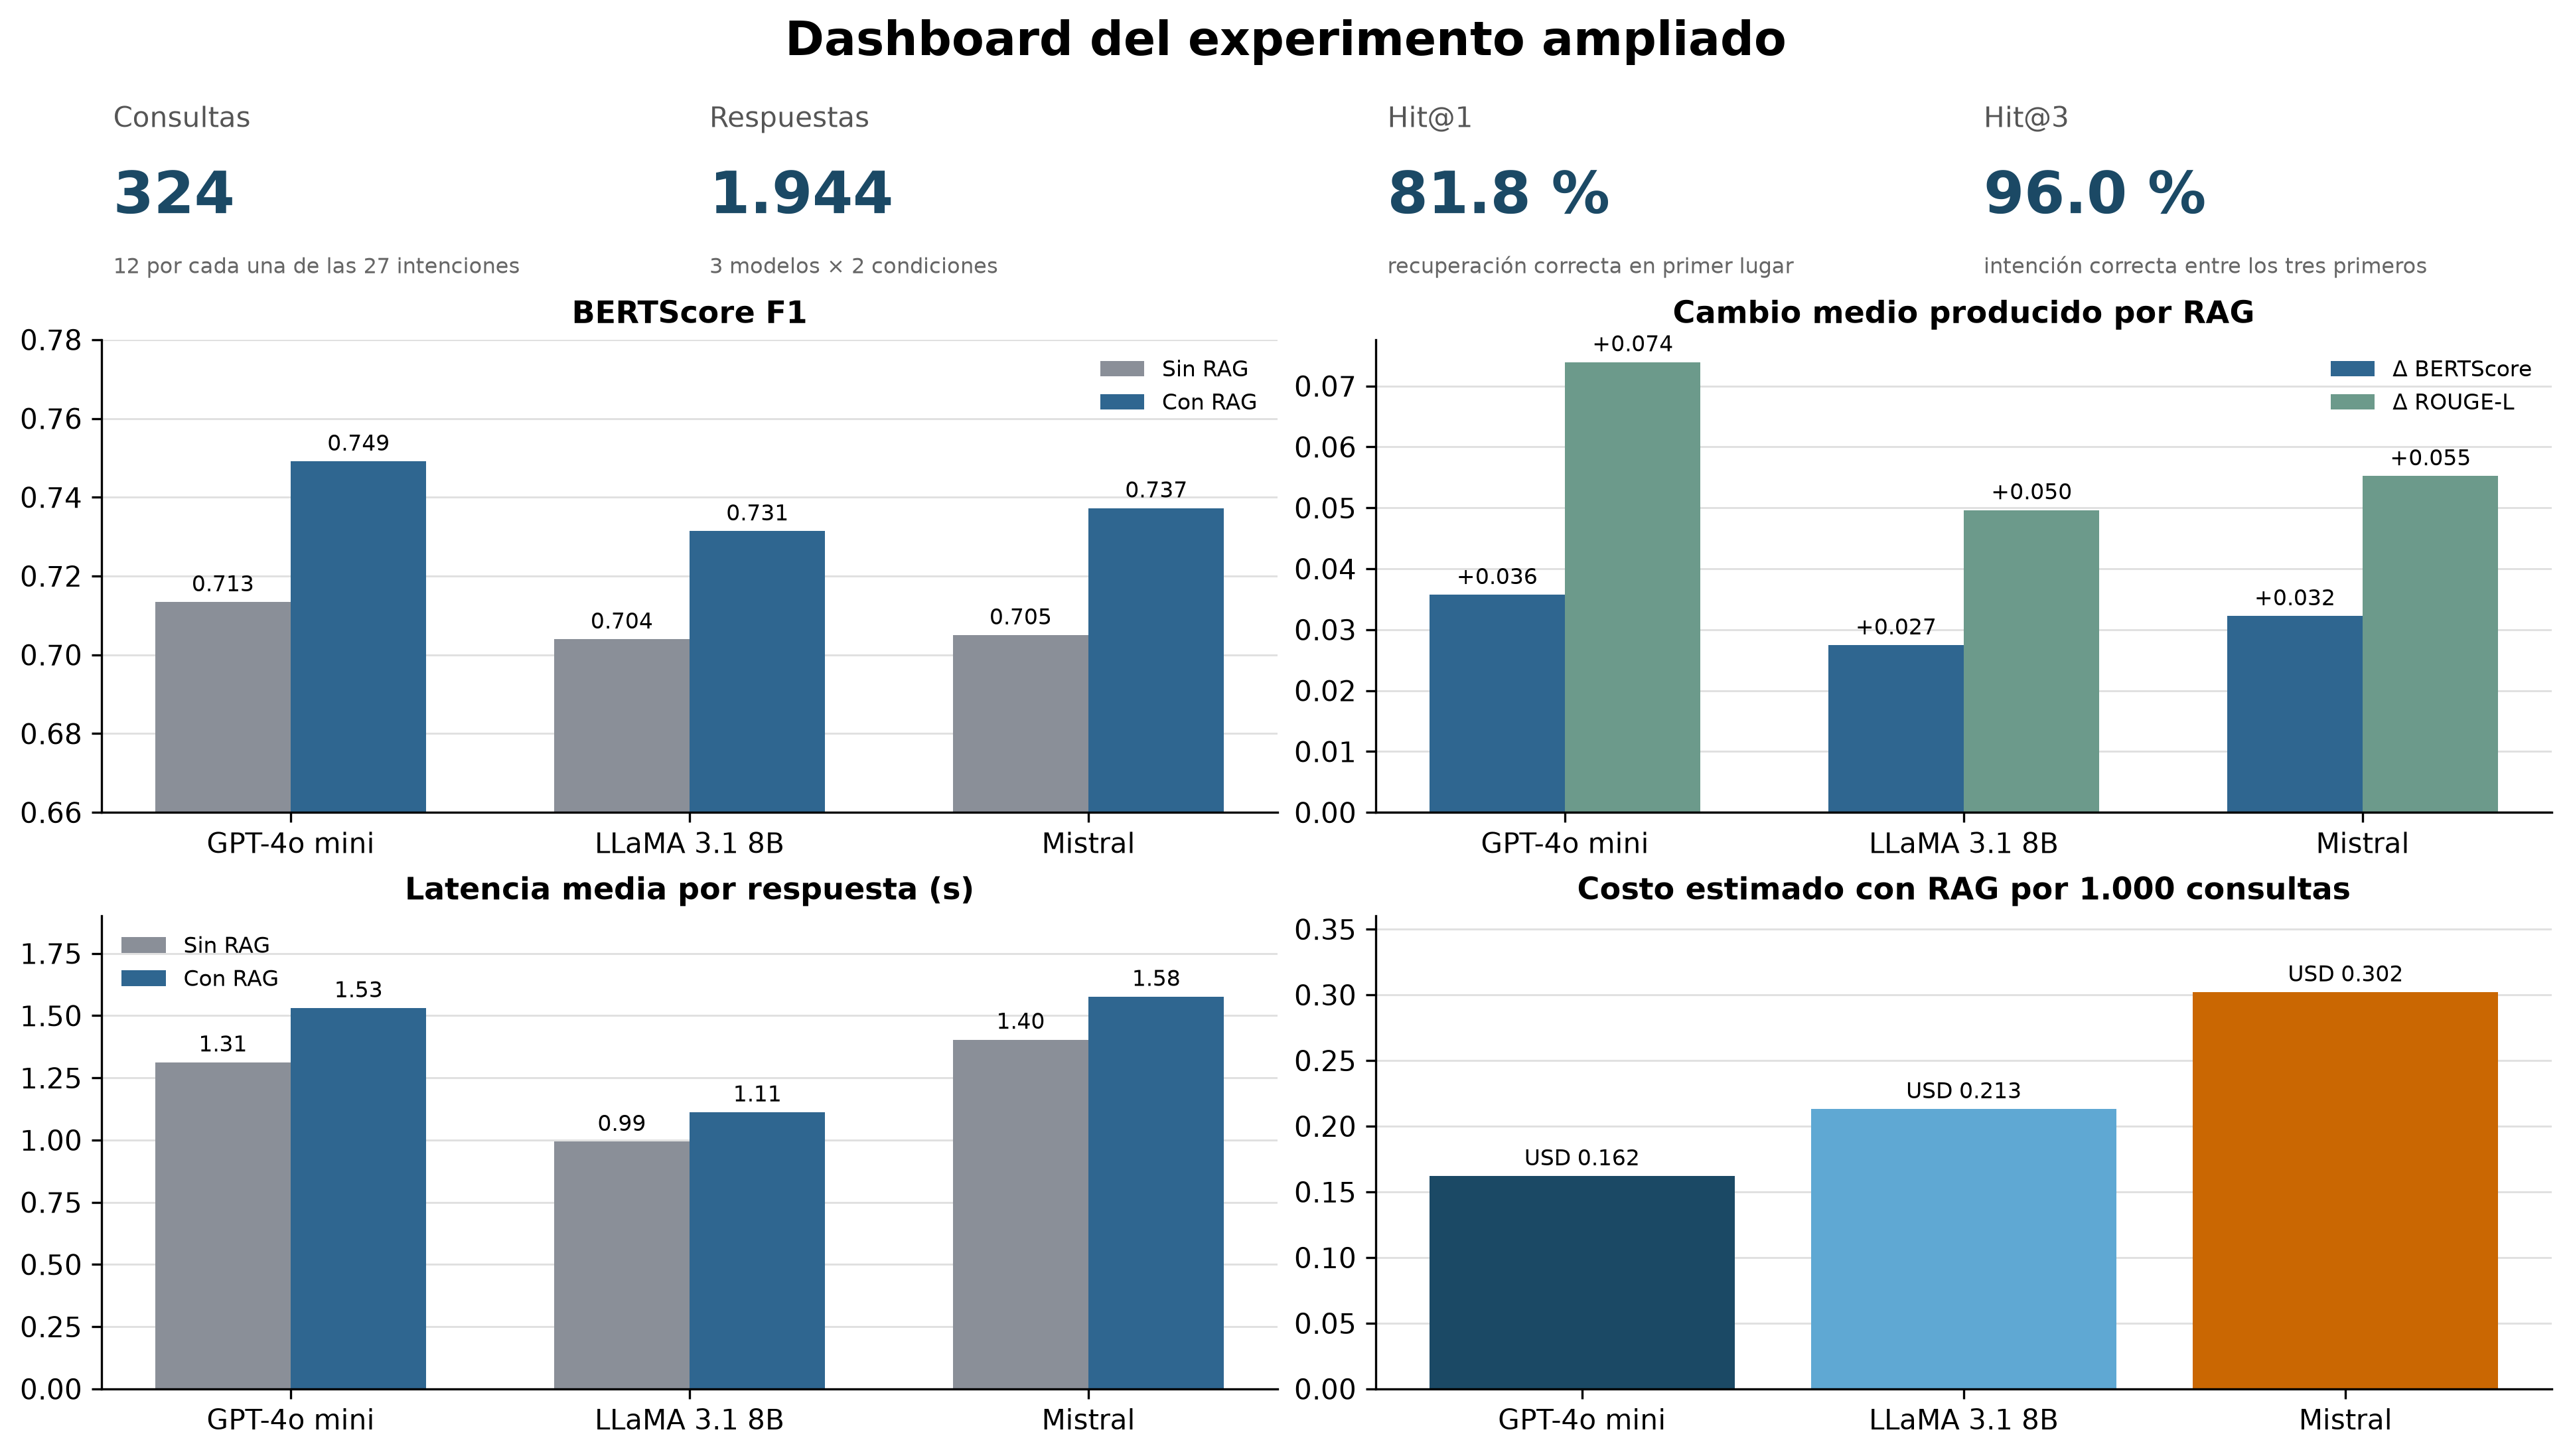

### Calidad por modelo y condición

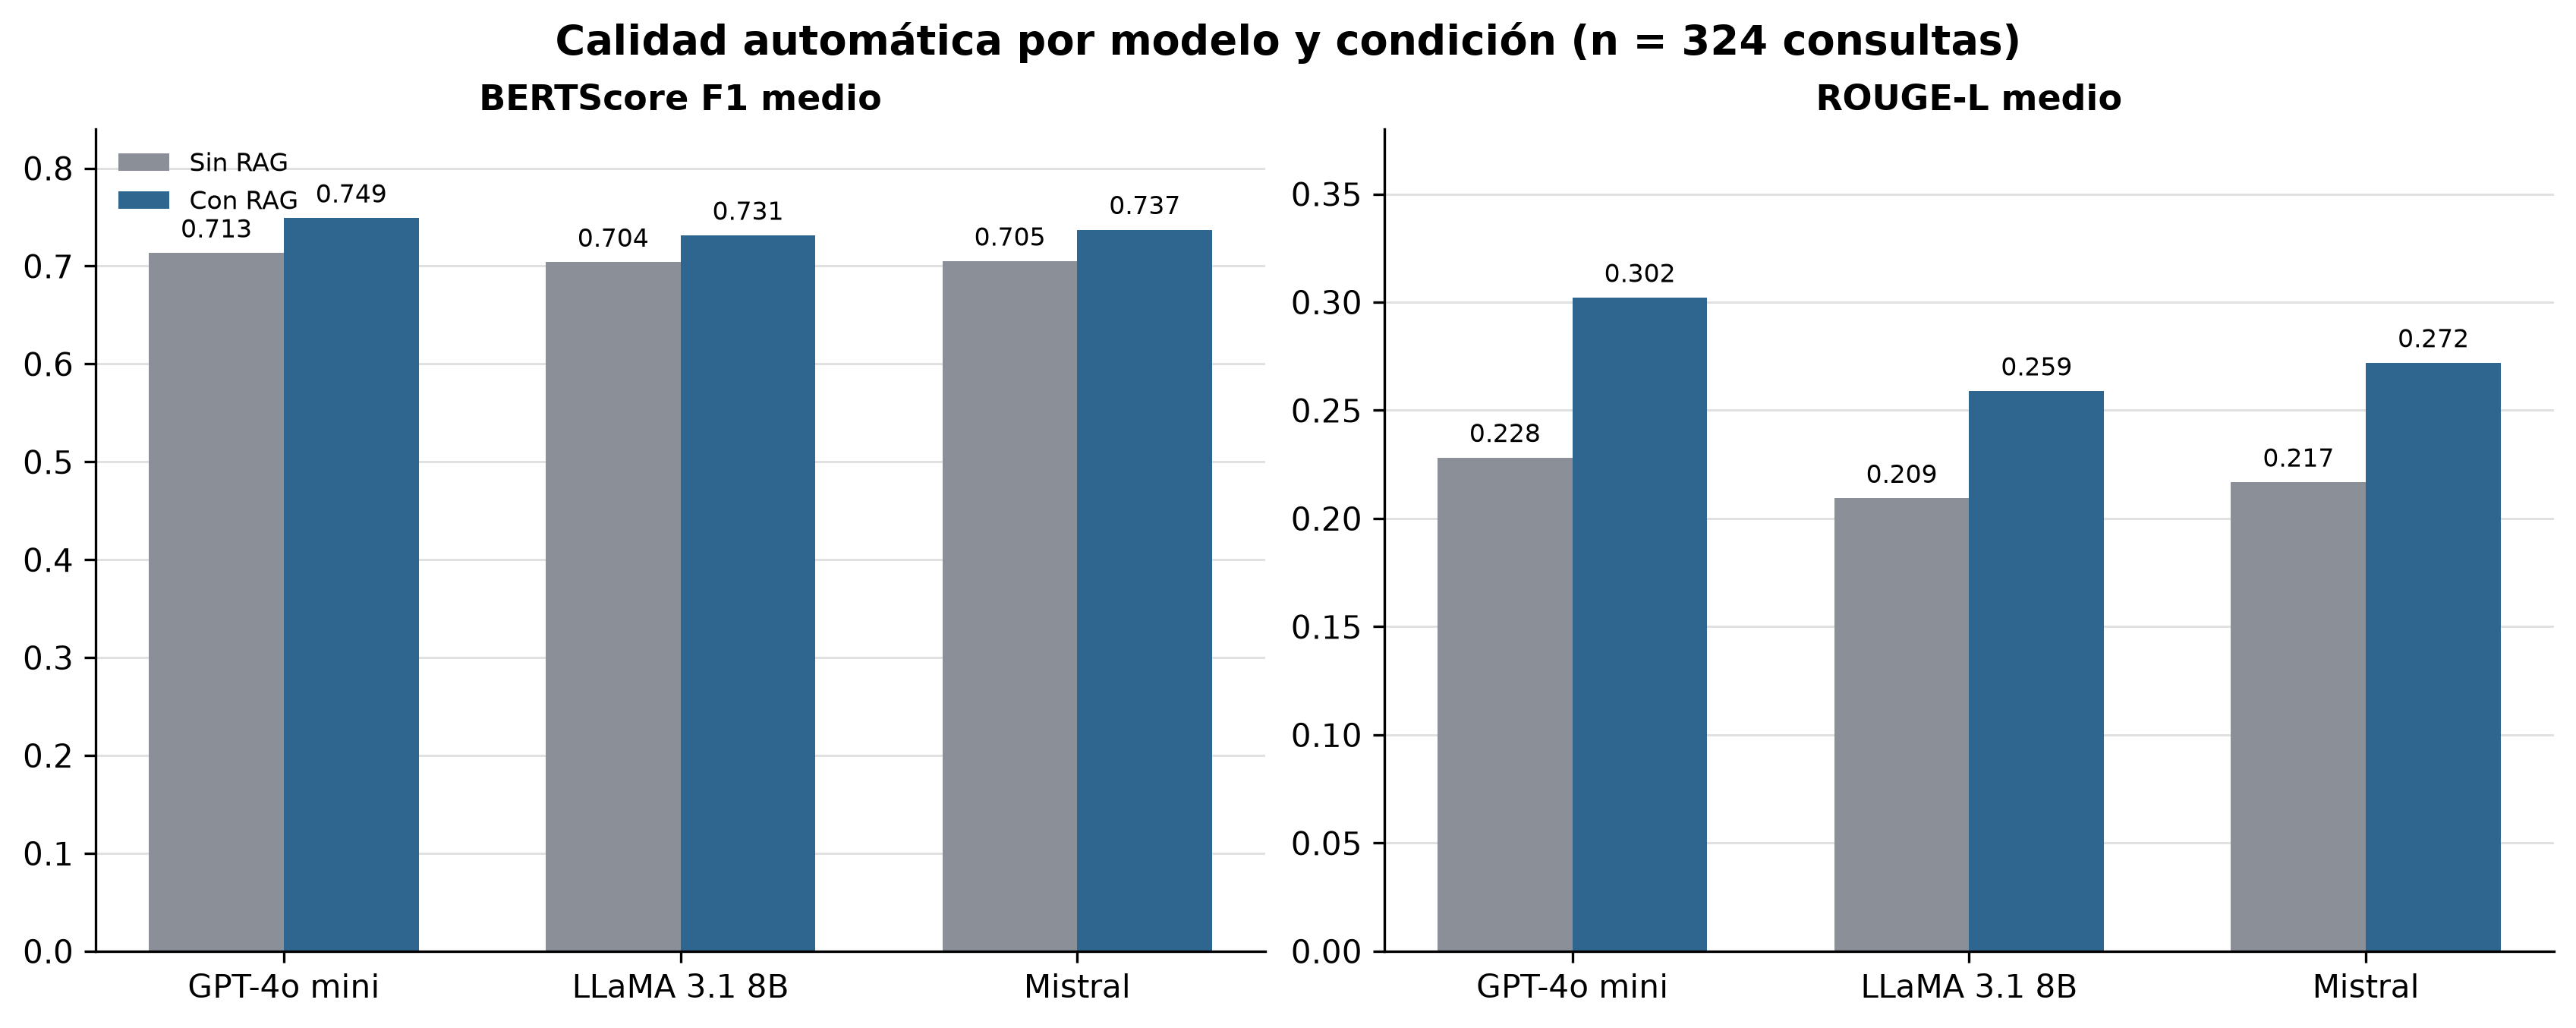

### Calidad, latencia y costo con RAG

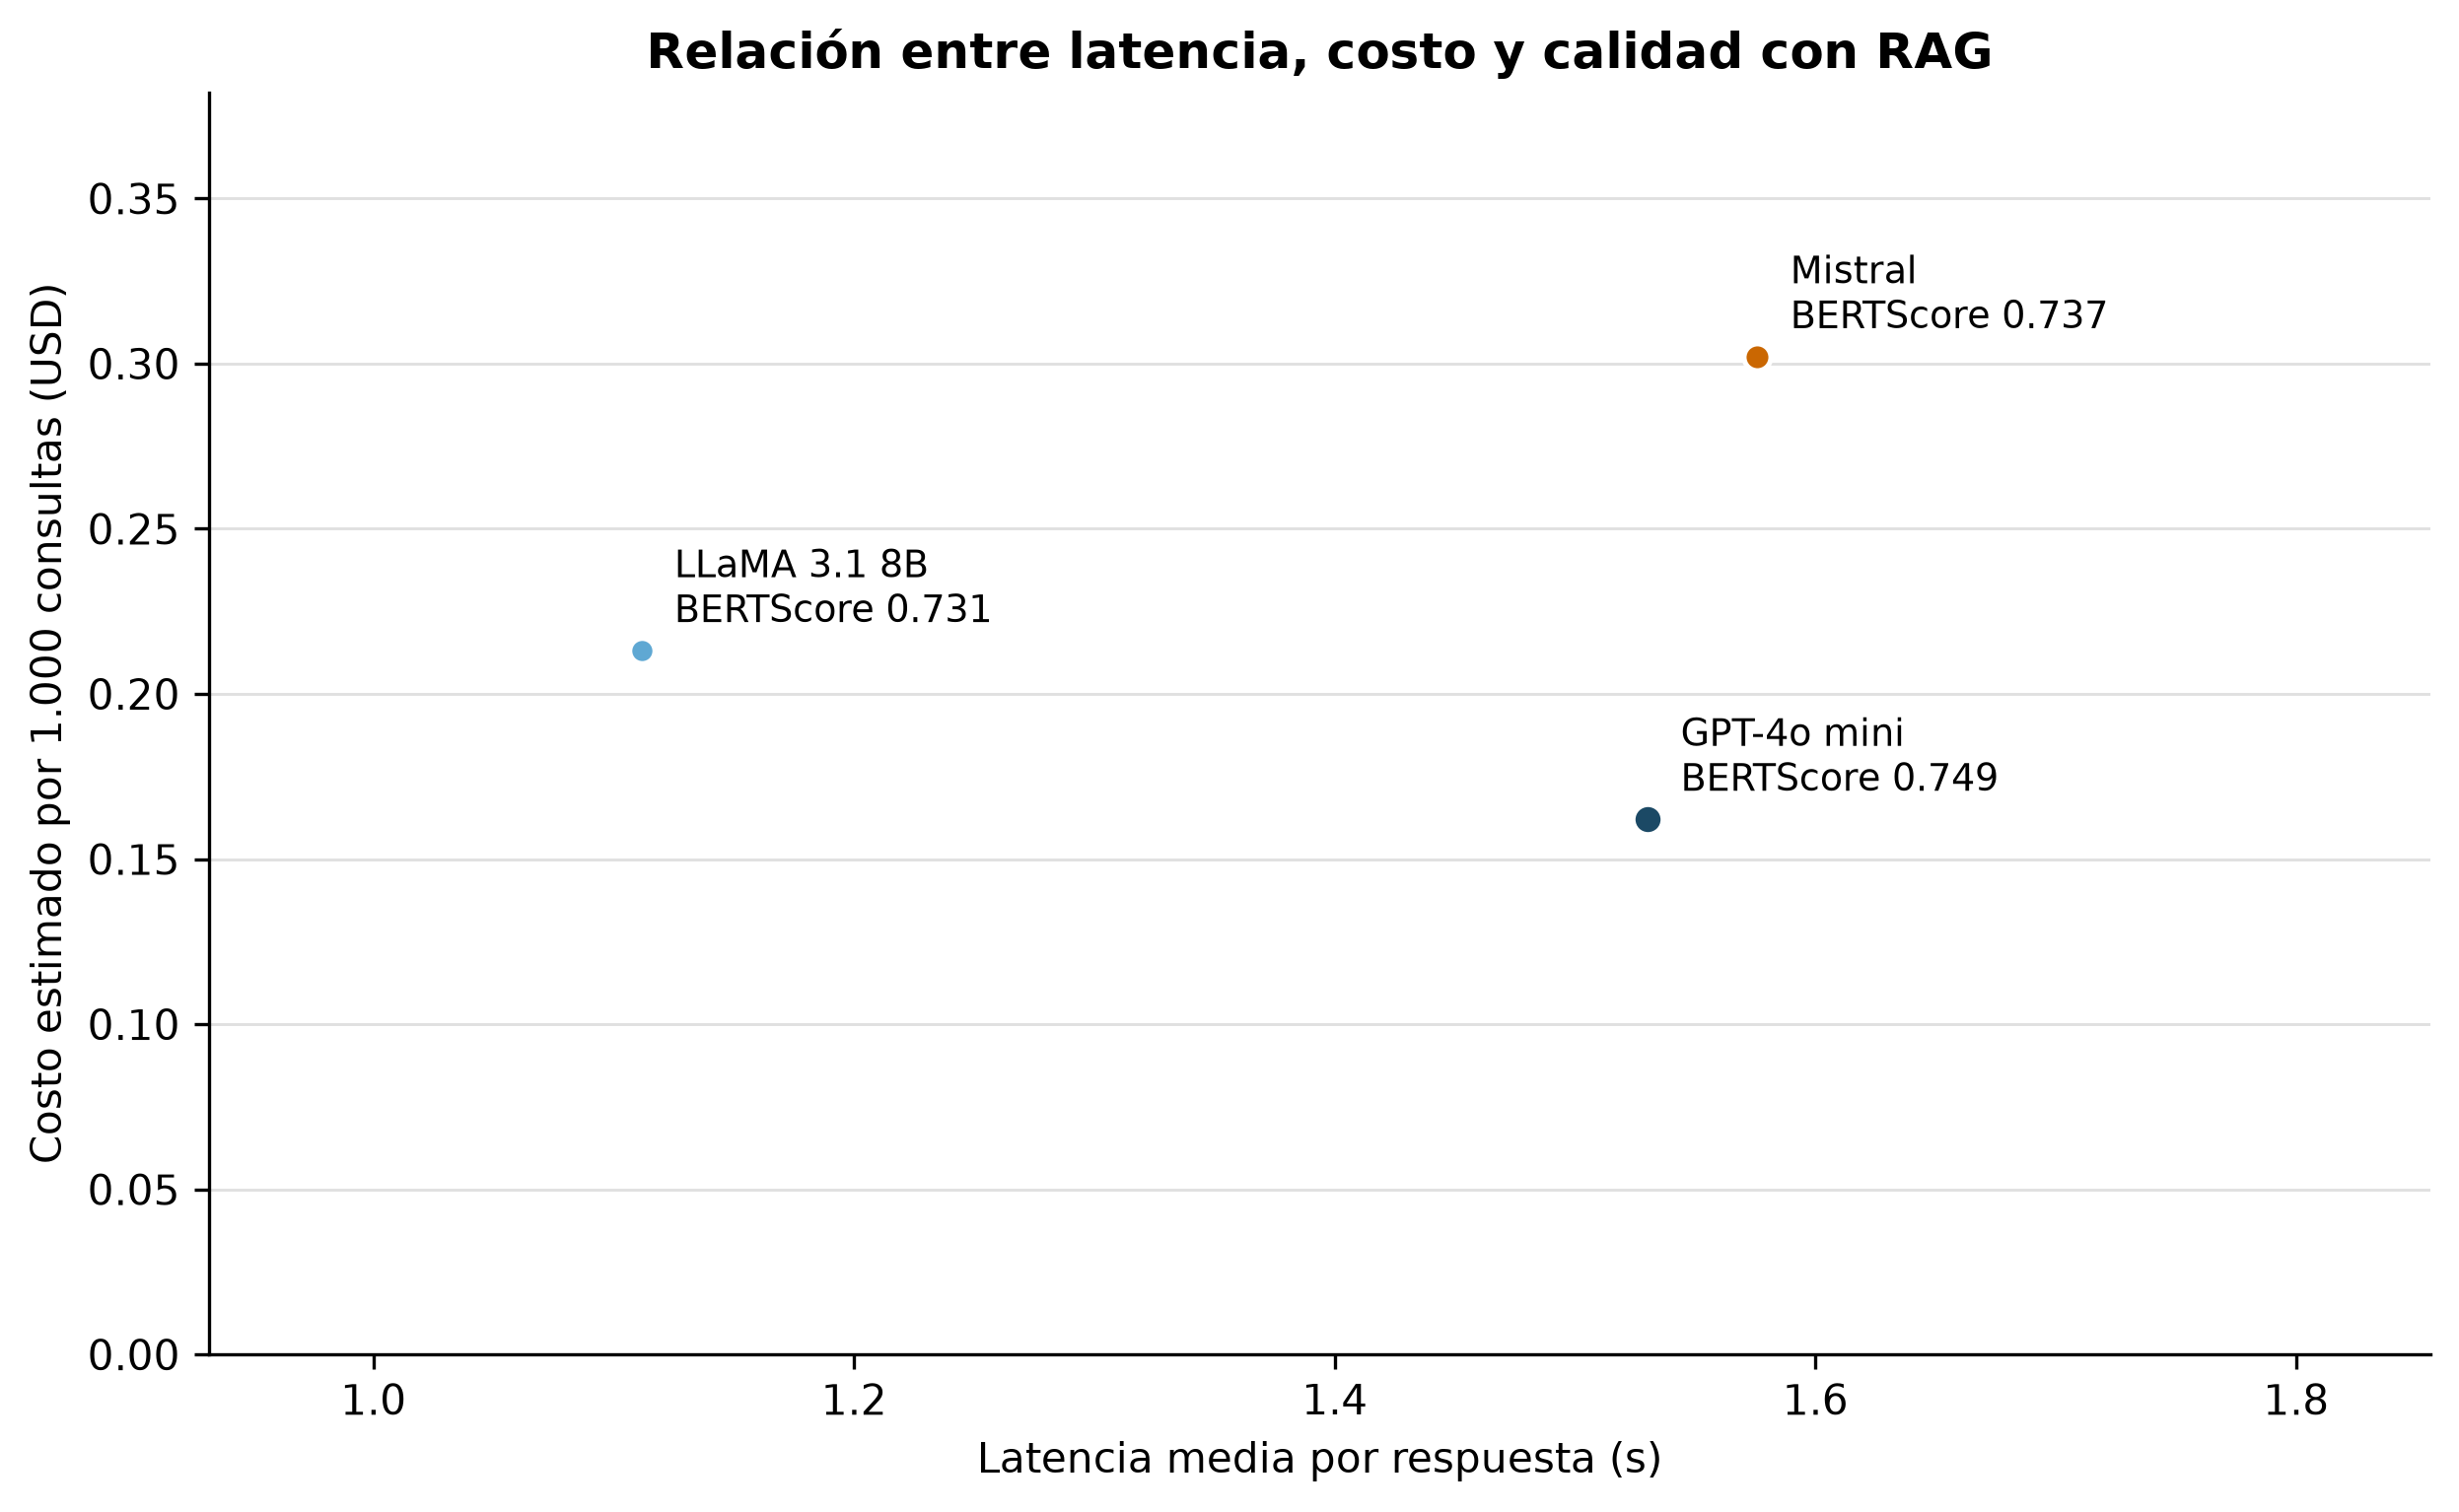

In [11]:
if REGENERAR_FIGURAS:
    ejecutar_script("generar_figuras_resultados.py")

for nombre, titulo in [
    ("dashboard_experimento_ampliado.png", "Dashboard general"),
    ("calidad_modelos_condicion.png", "Calidad por modelo y condición"),
    ("eficiencia_modelos_rag.png", "Calidad, latencia y costo con RAG"),
]:
    ruta = PROYECTO / "figuras" / nombre
    if ruta.exists():
        display(Markdown(f"### {titulo}"))
        display(Image(filename=str(ruta)))
    else:
        print(f"Falta {ruta}. Active REGENERAR_FIGURAS para producirla.")

## 10. Guía de selección según prioridad

In [12]:
from src.seleccion_modelo import construir_guia_seleccion

guia_seleccion = construir_guia_seleccion(resumen)
display(guia_seleccion)
display(Markdown(
    "La guía resume los resultados observados y no establece un ganador universal. "
    "La decisión final debe incorporar privacidad, infraestructura, volumen y la "
    "evaluación humana."
))

,prioridad,modelo_recomendado,evidencia,alcance
0,Mayor calidad semántica,GPT-4o mini,BERTScore F1 con RAG: 0.7491,Resultado medio sobre las 324 consultas del ex...
1,Menor costo estimado,GPT-4o mini,Costo por 1.000 consultas: USD 0.1620,Compara la API con el escenario cloud definido...
2,Menor latencia media,LLaMA 3.1 8B,Latencia media con RAG: 1.112 s,"Corresponde al equipo, la red y la sesión expe..."
3,Mayor calidad entre modelos abiertos,Mistral,BERTScore F1 con RAG: 0.7372,La decisión entre modelos abiertos también deb...


La guía resume los resultados observados y no establece un ganador universal. La decisión final debe incorporar privacidad, infraestructura, volumen y la evaluación humana.

## 11. Evaluación humana

Este notebook puede preparar los formularios y analizar respuestas ya
completadas, pero **no reemplaza a los evaluadores**. El análisis solo debe
activarse cuando dos personas hayan puntuado todas las filas.

,evaluador,filas_completas,total
0,1,324,324
1,2,324,324


Formularios completos; se reutilizan los resultados humanos integrados.


### Resultados humanos integrados

,modelo,condicion,n,correccion,utilidad,claridad,fidelidad,tasa_alucinacion,calidad_promedio
0,gpt-4o-mini,rag,54,4.370370,4.351852,4.796296,4.296296,0.074074,4.453704
1,gpt-4o-mini,sin_rag,54,4.157407,4.157407,4.898148,4.027778,0.083333,4.310185
2,llama-3.1-8b,rag,54,3.990741,3.962963,4.777778,3.935185,0.129630,4.166667
3,llama-3.1-8b,sin_rag,54,3.842593,3.870370,4.768519,3.722222,0.157407,4.050926
4,mistral,rag,54,4.351852,4.379630,4.731481,4.212963,0.055556,4.418981
5,mistral,sin_rag,54,4.305556,4.305556,4.814815,4.046296,0.064815,4.368056


### Acuerdo entre evaluadores

,metrica,n,acuerdo_exacto_pct,diferencia_absoluta_media,kappa_cohen,tipo_kappa
0,correccion_1_5,324,20.987654,1.086420,0.118313,ponderado_lineal
1,utilidad_1_5,324,17.592593,1.120370,0.131925,ponderado_lineal
2,claridad_1_5,324,71.913580,0.287037,0.143052,ponderado_lineal
3,fidelidad_contexto_1_5,324,15.740741,1.407407,0.066813,ponderado_lineal
4,alucinacion_0_1,324,83.024691,0.169753,0.053537,sin_ponderar


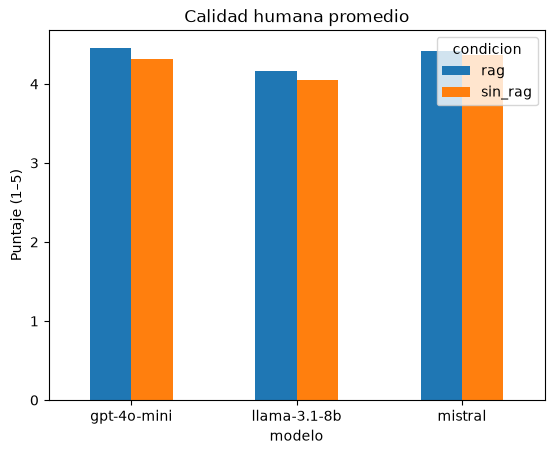

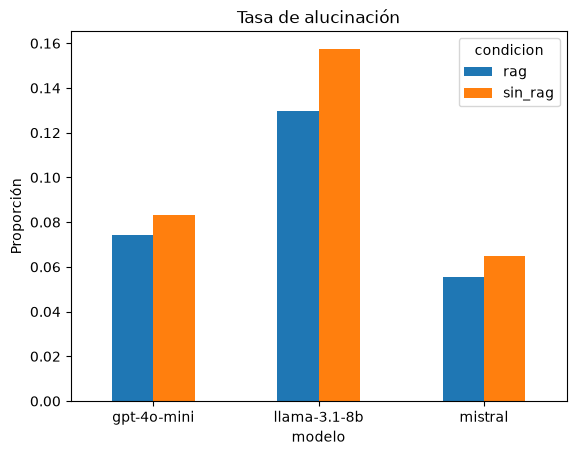

In [13]:
if PREPARAR_EVALUACION_HUMANA:
    ejecutar_script("preparar_evaluacion_humana.py")

columnas_puntaje = [
    "correccion_1_5", "utilidad_1_5", "claridad_1_5",
    "fidelidad_contexto_1_5", "alucinacion_0_1",
]
estado_humano = []
for numero in (1, 2):
    directorio_humano = PROYECTO / "evaluacion_humana"
    ruta_completa = directorio_humano / f"evaluador_{numero}_completado.xlsx"
    ruta = ruta_completa if ruta_completa.exists() else directorio_humano / f"evaluador_{numero}.xlsx"
    if ruta.exists():
        formulario = pd.read_excel(ruta, sheet_name="Evaluación")
        completas = int(formulario[columnas_puntaje].notna().all(axis=1).sum())
        estado_humano.append({"evaluador": numero, "filas_completas": completas, "total": len(formulario)})
    else:
        estado_humano.append({"evaluador": numero, "filas_completas": 0, "total": 324})

estado_humano = pd.DataFrame(estado_humano)
display(estado_humano)
evaluacion_humana_completa = bool((estado_humano["filas_completas"] == estado_humano["total"]).all())

if ANALIZAR_EVALUACION_HUMANA:
    if not evaluacion_humana_completa:
        raise RuntimeError("Los dos formularios deben estar completos antes de revelar y analizar los resultados.")
    ejecutar_script("analizar_evaluacion_humana.py")
else:
    print(
        "Análisis humano pendiente."
        if not evaluacion_humana_completa
        else "Formularios completos; se reutilizan los resultados humanos integrados."
    )

from src.acuerdo_humano import ARCHIVO_ACUERDO, ARCHIVO_RESUMEN

directorio_resultados_humanos = PROYECTO / "evaluacion_humana" / "resultados"
ruta_resumen_humano = directorio_resultados_humanos / ARCHIVO_RESUMEN
ruta_acuerdo_humano = directorio_resultados_humanos / ARCHIVO_ACUERDO

if ruta_resumen_humano.exists() and ruta_acuerdo_humano.exists():
    resumen_humano = pd.read_csv(ruta_resumen_humano)
    display(Markdown("### Resultados humanos integrados"))
    display(resumen_humano)
    resumen_humano.pivot(
        index="modelo", columns="condicion", values="calidad_promedio"
    ).plot.bar(title="Calidad humana promedio", ylabel="Puntaje (1–5)", rot=0)
    resumen_humano.pivot(
        index="modelo", columns="condicion", values="tasa_alucinacion"
    ).plot.bar(title="Tasa de alucinación", ylabel="Proporción", rot=0)
    display(Markdown("### Acuerdo entre evaluadores"))
    display(pd.read_csv(ruta_acuerdo_humano))
else:
    display(Markdown(
        "Los resultados humanos aparecerán automáticamente en esta sección "
        "después de completar y analizar ambos formularios."
    ))

## 12. Cierre de la ejecución

In [14]:
cierre_humano = (
    "La evidencia automática y humana está integrada y lista para reproducirse y presentarse."
    if evaluacion_humana_completa
    else "La evidencia automática está lista; falta completar la evaluación humana antes del cierre."
)
display(Markdown(
    f"""
### Estado final

- Muestra balanceada: **{len(muestra)} consultas**, {muestra['intent'].nunique()} intenciones.
- Experimento automático: **{len(crudos):,} respuestas**, {errores} errores.
- Recuperación: **Hit@1 {recuperacion['hit_top1'].mean():.1%}** y **Hit@3 {recuperacion['hit_top_k'].mean():.1%}**.
- Evaluación humana: **{'completa' if evaluacion_humana_completa else 'pendiente'}**.

{cierre_humano}
"""
))


### Estado final

- Muestra balanceada: **324 consultas**, 27 intenciones.
- Experimento automático: **1,944 respuestas**, 0 errores.
- Recuperación: **Hit@1 81.8%** y **Hit@3 96.0%**.
- Evaluación humana: **completa**.

La evidencia automática y humana está integrada y lista para reproducirse y presentarse.
